In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Impostazione dei percorsi coerente con la struttura del progetto
PROJECT_ROOT = Path.cwd().parent
DATASET_DIR = PROJECT_ROOT / "dataset" / "lastfm-dataset-1K"
LISTENING_FILE = DATASET_DIR / "userid-timestamp-artid-artname-traid-traname.tsv"

print(f"Caricamento dataset da: {LISTENING_FILE}")

# 2. Caricamento del dataset (ottimizzato)
df = pd.read_csv(
    LISTENING_FILE,
    sep='\t',
    header=None,
    names=['user_id', 'timestamp', 'artist_mbid', 'artist_name', 'track_mbid', 'track_name'],
    on_bad_lines='skip'
)

print("Conversione dei timestamp in formato datetime (potrebbe richiedere qualche minuto)...")
df['timestamp'] = pd.to_datetime(df['timestamp'])

print(f"Completato! Dataset caricato con successo: {len(df):,} righe.")

Caricamento dataset da: C:\Users\dales\OneDrive\Desktop\PROGETTO SII\music-discovery-CMAB\dataset\lastfm-dataset-1K\userid-timestamp-artid-artname-traid-traname.tsv
Conversione dei timestamp in formato datetime (potrebbe richiedere qualche minuto)...
Completato! Dataset caricato con successo: 19,098,853 righe.


Ordinamento del dataset per utente e traccia...
Calcolo dei delta temporali tra ascolti consecutivi...


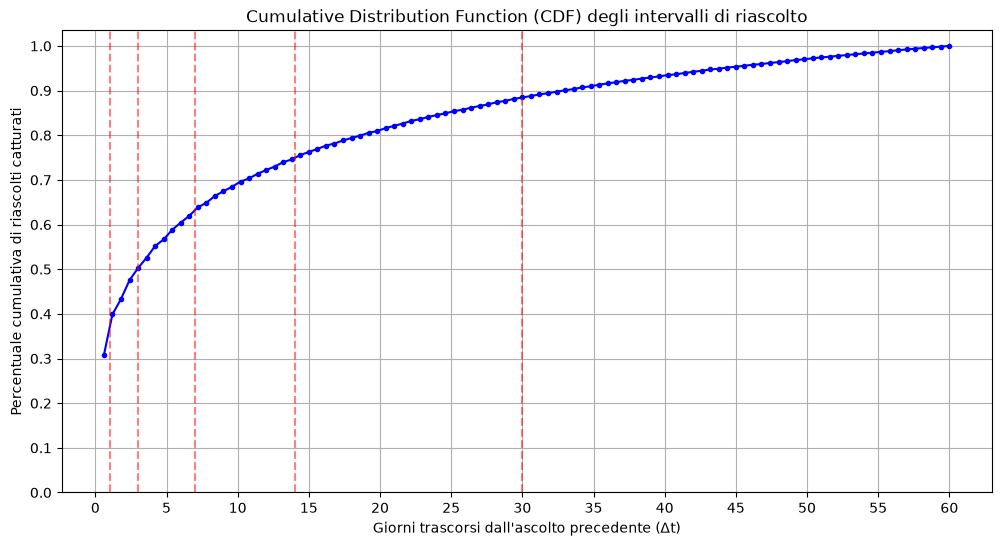


--- RISULTATI EMPIRICI PER LA SCELTA DEL REWARD ---
Percentuale di riascolti catturati per le finestre temporali chiave (rispetto al totale dei riascolti nel dataset):
Finestra di  1 giorni: 29.98% dei riascolti totali
Finestra di  3 giorni: 40.58% dei riascolti totali
Finestra di  7 giorni: 50.98% dei riascolti totali
Finestra di 14 giorni: 60.54% dei riascolti totali
Finestra di 30 giorni: 71.43% dei riascolti totali


In [2]:
# 1. Ordinamento cronologico rigoroso per utente e traccia
print("Ordinamento del dataset per utente e traccia...")
# Usiamo track_name per catturare i riascolti bypassando eventuali track_mbid mancanti
df_sorted = df.sort_values(by=['user_id', 'track_name', 'timestamp'])

# 2. Calcolo dei delta temporali vettorizzato
print("Calcolo dei delta temporali tra ascolti consecutivi...")
df_sorted['time_diff'] = df_sorted.groupby(['user_id', 'track_name'])['timestamp'].diff()

# 3. Conversione in giorni e rimozione dei primissimi ascolti (che non hanno un delta)
deltas_in_days = df_sorted['time_diff'].dt.total_seconds() / (24 * 3600)
deltas_in_days = deltas_in_days.dropna()

# 4. Creazione della CDF (filtrata a max 60 giorni per chiarezza visiva)
max_days = 60
deltas_filtered = deltas_in_days[deltas_in_days <= max_days]

count, bins_count = np.histogram(deltas_filtered, bins=100)
pdf = count / sum(count)
cdf = np.cumsum(pdf)

# 5. Plot del grafico
plt.figure(figsize=(12, 6))
plt.plot(bins_count[1:], cdf, marker='.', linestyle='-', color='b')

# Linee di riferimento strategiche per decidere \Delta
giorni_chiave = [1, 3, 7, 14, 30]
for g in giorni_chiave:
    plt.axvline(x=g, color='r', linestyle='--', alpha=0.5)

plt.title('Cumulative Distribution Function (CDF) degli intervalli di riascolto')
plt.xlabel('Giorni trascorsi dall\'ascolto precedente (Δt)')
plt.ylabel('Percentuale cumulativa di riascolti catturati')
plt.grid(True)
plt.xticks(np.arange(0, max_days + 1, 5))
plt.yticks(np.arange(0, 1.1, 0.1))
plt.show()

# 6. Estrazione dei dati quantitativi per giustificare la scelta all'esame
print("\n--- RISULTATI EMPIRICI PER LA SCELTA DEL REWARD ---")
print("Percentuale di riascolti catturati per le finestre temporali chiave (rispetto al totale dei riascolti nel dataset):")
total_reascolti = len(deltas_in_days)
for g in giorni_chiave:
    coverage = (deltas_in_days <= g).sum() / total_reascolti * 100
    print(f"Finestra di {g:2} giorni: {coverage:.2f}% dei riascolti totali")

Ordinamento cronologico generale per utente (indipendentemente dalla traccia)...
Calcolo dei gap temporali tra ascolti consecutivi...


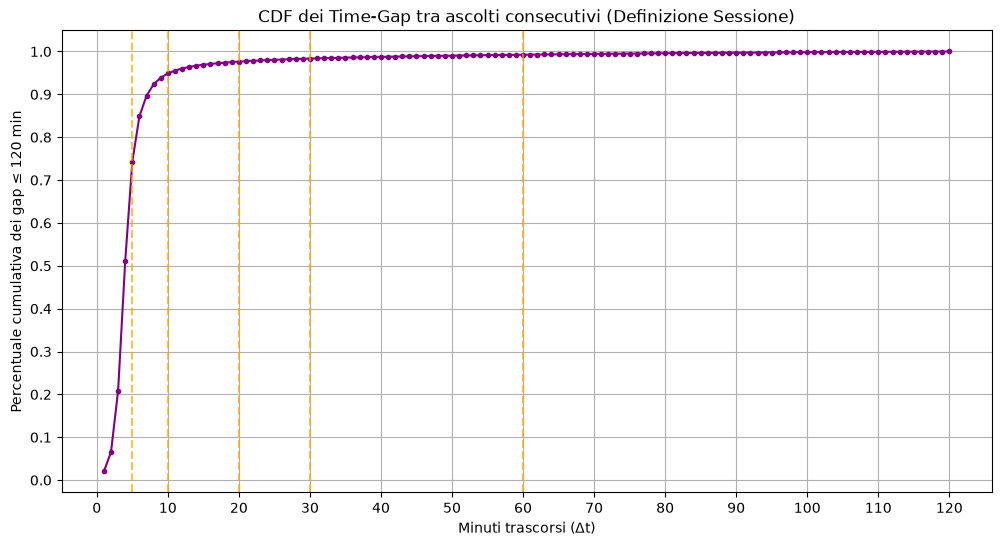


--- ANALISI SOGLIE PER SESSIONE (τ) ---
Rispetto a tutte le pause inferiori a 2 ore, ecco quanta percentuale viene coperta:
Gap entro i  5 minuti: 74.67% degli ascolti continuativi
Gap entro i 10 minuti: 94.89% degli ascolti continuativi
Gap entro i 20 minuti: 97.64% degli ascolti continuativi
Gap entro i 30 minuti: 98.34% degli ascolti continuativi
Gap entro i 60 minuti: 99.24% degli ascolti continuativi


In [3]:
import numpy as np
import matplotlib.pyplot as plt

print("Ordinamento cronologico generale per utente (indipendentemente dalla traccia)...")
# Ordiniamo solo per utente e timestamp per vedere l'attività sequenziale pura
df_sessions = df.sort_values(by=['user_id', 'timestamp'])

print("Calcolo dei gap temporali tra ascolti consecutivi...")
# Calcoliamo la differenza rispetto alla riga precedente, raggruppando per utente
df_sessions['gap_minutes'] = df_sessions.groupby('user_id')['timestamp'].diff().dt.total_seconds() / 60

# Rimuoviamo i NaN (il primo ascolto in assoluto di ogni utente)
gaps = df_sessions['gap_minutes'].dropna()

# Filtriamo per i gap inferiori a 120 minuti per concentrarci sulla micro-dinamica delle sessioni
max_minutes = 120
gaps_zoomed = gaps[gaps <= max_minutes]

# Creazione della CDF
count, bins_count = np.histogram(gaps_zoomed, bins=120)
pdf = count / sum(count)
cdf = np.cumsum(pdf)

# Plot del grafico
plt.figure(figsize=(12, 6))
plt.plot(bins_count[1:], cdf, marker='.', linestyle='-', color='purple')

# Linee di riferimento per le soglie candidate indicate nel progetto
soglie_minuti = [5, 10, 20, 30, 60]
for m in soglie_minuti:
    plt.axvline(x=m, color='orange', linestyle='--', alpha=0.7)

plt.title('CDF dei Time-Gap tra ascolti consecutivi (Definizione Sessione)')
plt.xlabel('Minuti trascorsi (Δt)')
plt.ylabel('Percentuale cumulativa dei gap ≤ 120 min')
plt.grid(True)
plt.xticks(np.arange(0, max_minutes + 1, 10))
plt.yticks(np.arange(0, 1.1, 0.1))
plt.show()

# Estrazione dei dati quantitativi per il documento
print("\n--- ANALISI SOGLIE PER SESSIONE (τ) ---")
print("Rispetto a tutte le pause inferiori a 2 ore, ecco quanta percentuale viene coperta:")
total_zoomed_gaps = len(gaps_zoomed)
for m in soglie_minuti:
    coverage = (gaps_zoomed <= m).sum() / total_zoomed_gaps * 100
    print(f"Gap entro i {m:2} minuti: {coverage:.2f}% degli ascolti continuativi")

Calcolo dell'attività temporale per ciascun utente...


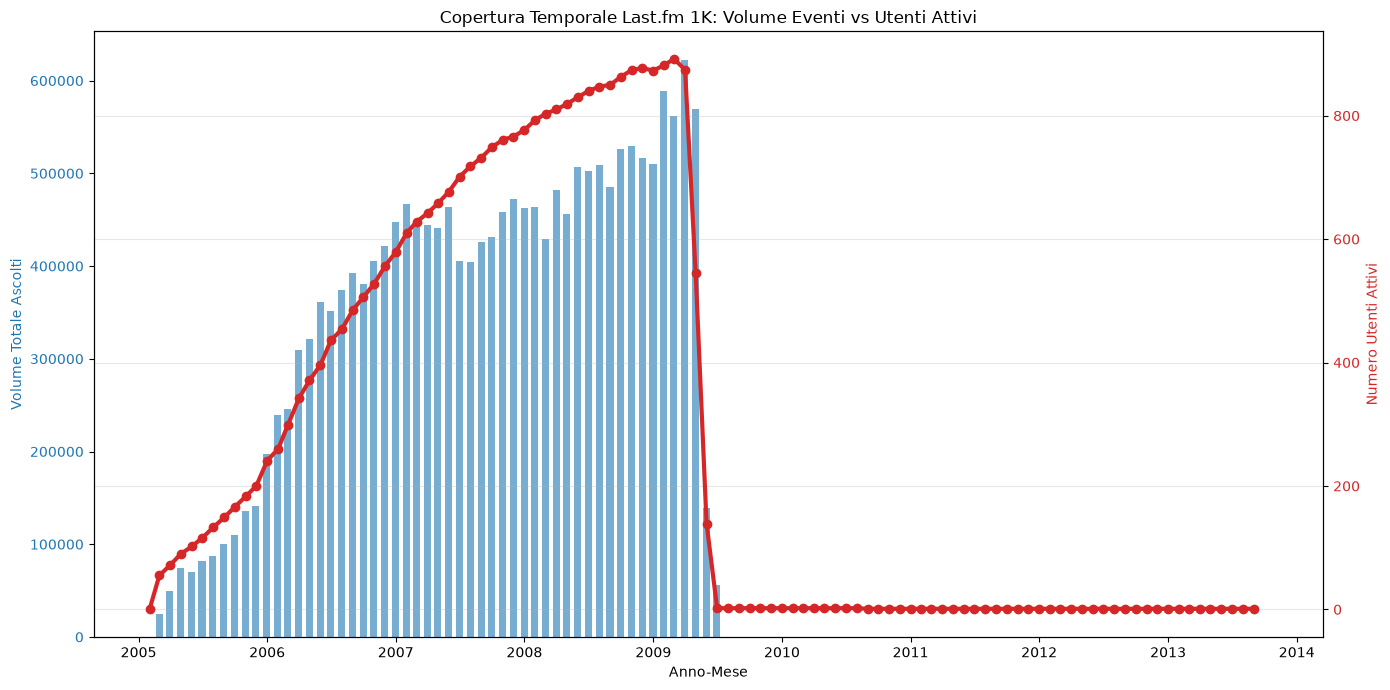


--- ANALISI COPERTURA PER DATE CHIAVE ---

Se posizioniamo il taglio (Training / Test) al 2007-12-31:
 - Utenti con storico (Warm-up H_u): 793
 - Utenti con test futuro: 976
 - Utenti VALIDI per l'esperimento (hanno sia train che test): 777 su 992 totali

Se posizioniamo il taglio (Training / Test) al 2008-06-30:
 - Utenti con storico (Warm-up H_u): 871
 - Utenti con test futuro: 960
 - Utenti VALIDI per l'esperimento (hanno sia train che test): 839 su 992 totali

Se posizioniamo il taglio (Training / Test) al 2008-12-31:
 - Utenti con storico (Warm-up H_u): 944
 - Utenti con test futuro: 921
 - Utenti VALIDI per l'esperimento (hanno sia train che test): 873 su 992 totali


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

# 1. Caricamento Dati (come nei notebook precedenti)
PROJECT_ROOT = Path.cwd().parent
DATASET_DIR = PROJECT_ROOT / "dataset" / "lastfm-dataset-1K"
LISTENING_FILE = DATASET_DIR / "userid-timestamp-artid-artname-traid-traname.tsv"

df = pd.read_csv(
    LISTENING_FILE, sep='\t', header=None,
    names=['user_id', 'timestamp', 'artist_mbid', 'artist_name', 'track_mbid', 'track_name'],
    on_bad_lines='skip'
)
df['timestamp'] = pd.to_datetime(df['timestamp'])

# 2. Analisi del Ciclo di Vita degli Utenti (Min e Max timestamp)
print("Calcolo dell'attività temporale per ciascun utente...")
user_lifespan = df.groupby('user_id')['timestamp'].agg(['min', 'max']).reset_index()
user_lifespan.columns = ['user_id', 'first_event', 'last_event']

# 3. Costruzione della griglia temporale mensile (dal 2005 al 2010)
min_date = df['timestamp'].min().replace(day=1)
max_date = df['timestamp'].max().replace(day=1)
months_grid = pd.date_range(start=min_date, end=max_date, freq='MS')

# 4. Conteggio degli utenti "Attivi" per ogni mese
# Un utente è considerato "attivo" in un mese se quel mese cade tra il suo primo e ultimo ascolto assoluto
active_users_per_month = []
for month in months_grid:
    active_count = ((user_lifespan['first_event'] <= month) & (user_lifespan['last_event'] >= month)).sum()
    active_users_per_month.append(active_count)

# 5. Volume globale degli eventi per mese (per individuare il crollo dei dati)
events_per_month = df.set_index('timestamp').resample('ME').size()

# 6. Plot combinato: Utenti Attivi vs Volume Eventi
fig, ax1 = plt.subplots(figsize=(14, 7))

# Asse Sinistro: Volume eventi
color1 = 'tab:blue'
ax1.set_xlabel('Anno-Mese')
ax1.set_ylabel('Volume Totale Ascolti', color=color1)
ax1.bar(events_per_month.index, events_per_month.values, color=color1, alpha=0.6, width=20, label='Eventi mensili')
ax1.tick_params(axis='y', labelcolor=color1)

# Asse Destro: Utenti attivi
ax2 = ax1.twinx()
color2 = 'tab:red'
ax2.set_ylabel('Numero Utenti Attivi', color=color2)
ax2.plot(months_grid, active_users_per_month, color=color2, linewidth=3, marker='o', label='Utenti attivi')
ax2.tick_params(axis='y', labelcolor=color2)

# Formattazione asse X per mostrare bene gli anni
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.title('Copertura Temporale Last.fm 1K: Volume Eventi vs Utenti Attivi')
fig.tight_layout()
plt.grid(True, alpha=0.3)
plt.show()

# 7. Estrazione quantitativa per giustificare lo split
print("\n--- ANALISI COPERTURA PER DATE CHIAVE ---")
candidate_splits = ['2007-12-31', '2008-06-30', '2008-12-31']
for date_str in candidate_splits:
    # Aggiungiamo la localizzazione UTC per pareggiare il formato del dataset
    split_date = pd.to_datetime(date_str).tz_localize('UTC')
    
    # Quanti utenti hanno INIZIATO prima di questa data? (Hanno potenziale storico)
    users_with_history = (user_lifespan['first_event'] <= split_date).sum()
    # Quanti utenti continuano ad avere eventi DOPO questa data? (Hanno potenziale di test)
    users_with_future = (user_lifespan['last_event'] > split_date).sum()
    # Quanti utenti soddisfano entrambe le condizioni?
    valid_users = ((user_lifespan['first_event'] <= split_date) & (user_lifespan['last_event'] > split_date)).sum()
    
    print(f"\nSe posizioniamo il taglio (Training / Test) al {date_str}:")
    print(f" - Utenti con storico (Warm-up H_u): {users_with_history}")
    print(f" - Utenti con test futuro: {users_with_future}")
    print(f" - Utenti VALIDI per l'esperimento (hanno sia train che test): {valid_users} su {len(user_lifespan)} totali")

In [3]:
import pandas as pd
import numpy as np

# 1. Ordinamento per utente e timestamp
print("Ordinamento del dataset...")
df_sorted = df.sort_values(by=['user_id', 'timestamp']).copy()

# 2. Implementazione della soglia di sessione (\tau = 10 minuti)
print("Sessionizzazione in corso (\tau = 10 minuti)...")
df_sorted['gap_minutes'] = df_sorted.groupby('user_id')['timestamp'].diff().dt.total_seconds() / 60

# Una riga è l'inizio di una nuova sessione se è il primo evento dell'utente o se il gap > 10
df_sorted['is_new_session'] = (df_sorted['gap_minutes'] > 10) | df_sorted['gap_minutes'].isna()

# Creiamo un ID univoco globale per ogni sessione con cumsum()
df_sorted['session_id'] = df_sorted['is_new_session'].cumsum()

# 3. Estrazione dei Decision Points (l'inizio di ogni sessione)
decision_points = df_sorted.groupby(['user_id', 'session_id'])['timestamp'].min().reset_index()

# 4. Definizione rigorosa dei confini temporali (Tz-aware UTC per evitare errori)
t_train = pd.to_datetime('2008-12-31 23:59:59').tz_localize('UTC')
t_val = pd.to_datetime('2009-02-28 23:59:59').tz_localize('UTC')
t_test = pd.to_datetime('2009-05-05 23:59:59').tz_localize('UTC')

# 5. Assegnazione delle sessioni ai periodi
condlist = [
    decision_points['timestamp'] <= t_train,
    decision_points['timestamp'] <= t_val,
    decision_points['timestamp'] <= t_test
]
choicelist = ['Train', 'Val', 'Test']
decision_points['period'] = np.select(condlist, choicelist, default='Drop')

# 6. Costruzione della matrice Utente x Periodo (Conteggio sessioni)
print("Calcolo delle statistiche di sessione per utente...")
user_sessions = decision_points.pivot_table(
    index='user_id', 
    columns='period', 
    aggfunc='size', 
    fill_value=0
)

# Filtriamo solo gli utenti che hanno almeno una sessione nel Train
valid_users_df = user_sessions[user_sessions['Train'] > 0]

# 7. Analisi della Distribuzione per definire N_min
print("\n--- DISTRIBUZIONE DEL NUMERO DI SESSIONI PER UTENTE ---")
print("Percentili del numero di sessioni (Decision Points) nei vari periodi:\n")
columns_to_show = ['Train', 'Val', 'Test']
# Mostriamo solo le colonne presenti
columns_to_show = [c for c in columns_to_show if c in valid_users_df.columns]

print(valid_users_df[columns_to_show].describe(percentiles=[0.25, 0.5, 0.75, 0.90]).astype(int))

print("\n--- TEST SOGLIE N_min ---")
# Proviamo alcune soglie ipotetiche per vedere quanti utenti sopravvivono
soglie_prova = [1, 3, 5, 10]
for n in soglie_prova:
    utenti_ok = len(valid_users_df[
        (valid_users_df['Train'] >= n) & 
        (valid_users_df['Val'] >= n) & 
        (valid_users_df['Test'] >= n)
    ])
    print(f"Utenti con almeno {n} sessioni in TUTTI e tre i periodi: {utenti_ok} su {len(valid_users_df)}")

Ordinamento del dataset...
Sessionizzazione in corso (	au = 10 minuti)...
Calcolo delle statistiche di sessione per utente...

--- DISTRIBUZIONE DEL NUMERO DI SESSIONI PER UTENTE ---
Percentili del numero di sessioni (Decision Points) nei vari periodi:

period  Train   Val  Test
count     944   944   944
mean     1420    95    98
std      1498   125   125
min         1     0     0
25%       327     0     1
50%       961    45    47
75%      2070   154   155
90%      3569   248   266
max      9528  1147   779

--- TEST SOGLIE N_min ---
Utenti con almeno 1 sessioni in TUTTI e tre i periodi: 668 su 944
Utenti con almeno 3 sessioni in TUTTI e tre i periodi: 622 su 944
Utenti con almeno 5 sessioni in TUTTI e tre i periodi: 602 su 944
Utenti con almeno 10 sessioni in TUTTI e tre i periodi: 571 su 944


In [7]:
import pandas as pd
import numpy as np

# 1. Ispezione granulare delle code della distribuzione
print("--- DISTRIBUZIONE GRANULARE DELLE SESSIONI (PERCENTILI) ---\n")
percentiles = [0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
detailed_desc = valid_users_df[['Train', 'Val', 'Test']].describe(percentiles=percentiles).astype(int)
print(detailed_desc)

# 2. Analisi d'impatto delle soglie N_min sulla popolazione e sulla stabilità valutativa
print("\n--- IMPATTO DELLE SOGLIE N_min SULLA POPOLAZIONE VALUTABILE ---\n")
soglie_n = [1, 5, 10, 20]
total_users_dataset = 992 # Il bacino storico totale del dataset 1K

for n in soglie_n:
    # Applichiamo il filtro congiunto sui tre periodi
    mask = (valid_users_df['Train'] >= n) & (valid_users_df['Val'] >= n) & (valid_users_df['Test'] >= n)
    df_filtered = valid_users_df[mask]
    
    utenti_rimasti = len(df_filtered)
    percentuale = (utenti_rimasti / total_users_dataset) * 100
    
    # Calcoliamo come varia la ricchezza delle interazioni per i "sopravvissuti"
    mediana_val = df_filtered['Val'].median()
    mediana_test = df_filtered['Test'].median()
    media_val = df_filtered['Val'].mean()
    media_test = df_filtered['Test'].mean()
    
    print(f"Soglia N_min >= {n}:")
    print(f"  - Utenti mantenuti: {utenti_rimasti} ({percentuale:.1f}% del totale originario)")
    print(f"  - Decision Points (Validation): Mediana = {mediana_val:.0f}, Media = {media_val:.1f}")
    print(f"  - Decision Points (Test)      : Mediana = {mediana_test:.0f}, Media = {media_test:.1f}\n")

--- DISTRIBUZIONE GRANULARE DELLE SESSIONI (PERCENTILI) ---

period  Train   Val  Test
count     944   944   944
mean     1420    95    98
std      1498   125   125
min         1     0     0
10%        68     0     0
25%       327     0     1
50%       961    45    47
75%      2070   154   155
90%      3569   248   266
95%      4110   324   351
99%      6782   547   541
max      9528  1147   779

--- IMPATTO DELLE SOGLIE N_min SULLA POPOLAZIONE VALUTABILE ---

Soglia N_min >= 1:
  - Utenti mantenuti: 668 (67.3% del totale originario)
  - Decision Points (Validation): Mediana = 102, Media = 134.0
  - Decision Points (Test)      : Mediana = 97, Media = 135.3

Soglia N_min >= 5:
  - Utenti mantenuti: 602 (60.7% del totale originario)
  - Decision Points (Validation): Mediana = 118, Media = 147.1
  - Decision Points (Test)      : Mediana = 107, Media = 147.6

Soglia N_min >= 10:
  - Utenti mantenuti: 571 (57.6% del totale originario)
  - Decision Points (Validation): Mediana = 126, Media =

In [4]:
import pandas as pd
import numpy as np

# Assumo che 'decision_points' sia ancora in memoria con le colonne ['user_id', 'timestamp']
print("Ricalcolo dei Decision Points utilizzabili (con buffer di 7 giorni per il reward)...")

# 1. Definiamo i confini ESTREMI dei dati (per il reward)
t_val_end_data = pd.to_datetime('2009-02-28 23:59:59').tz_localize('UTC')
t_test_end_data = pd.to_datetime('2009-05-05 23:59:59').tz_localize('UTC')

# 2. Definiamo i confini UTILI per le decisioni (arretrati di 7 giorni)
buffer_days = pd.Timedelta(days=7)
t_train_end_decision = pd.to_datetime('2008-12-31 23:59:59').tz_localize('UTC') # Il train non genera reward, non serve buffer
t_val_end_decision = t_val_end_data - buffer_days
t_test_end_decision = t_test_end_data - buffer_days

# 3. Ria-assegnazione delle sessioni tenendo conto dei "Buchi Rossi" (i 7 giorni finali in cui non si decide)
condlist_usable = [
    decision_points['timestamp'] <= t_train_end_decision,
    (decision_points['timestamp'] > t_train_end_decision) & (decision_points['timestamp'] <= t_val_end_decision),
    (decision_points['timestamp'] > t_val_end_data) & (decision_points['timestamp'] <= t_test_end_decision)
]
choicelist_usable = ['Train_usable', 'Val_usable', 'Test_usable']
decision_points['period_usable'] = np.select(condlist_usable, choicelist_usable, default='Drop_Buffer')

# 4. Ricostruzione della matrice Utente x Periodo
user_sessions_usable = decision_points.pivot_table(
    index='user_id', 
    columns='period_usable', 
    aggfunc='size', 
    fill_value=0
)

# 5. Verifica della soglia N_min = 10 sulle nuove sessioni
n = 10
mask_usable = (
    (user_sessions_usable.get('Train_usable', 0) >= n) & 
    (user_sessions_usable.get('Val_usable', 0) >= n) & 
    (user_sessions_usable.get('Test_usable', 0) >= n)
)

utenti_finali = len(user_sessions_usable[mask_usable])
total_users = 992

print(f"\n--- VERDETTO FINALE UTENTI VALUTABILI ---")
print(f"Applicando N_min >= {n} sui periodi decurtati dal buffer di 7 giorni:")
print(f"Utenti Sopravvissuti: {utenti_finali} (rispetto ai 571 calcolati in precedenza)")

# Mostriamo le mediane per assicurarci che non siano crollate
if utenti_finali > 0:
    df_final = user_sessions_usable[mask_usable]
    print(f"\nNuove Mediane Decision Points (solo per i {utenti_finali} utenti):")
    print(f"  - Validation Usable: {df_final['Val_usable'].median():.0f}")
    print(f"  - Test Usable      : {df_final['Test_usable'].median():.0f}")

Ricalcolo dei Decision Points utilizzabili (con buffer di 7 giorni per il reward)...

--- VERDETTO FINALE UTENTI VALUTABILI ---
Applicando N_min >= 10 sui periodi decurtati dal buffer di 7 giorni:
Utenti Sopravvissuti: 561 (rispetto ai 571 calcolati in precedenza)

Nuove Mediane Decision Points (solo per i 561 utenti):
  - Validation Usable: 111
  - Test Usable      : 113


In [1]:
import pandas as pd
import numpy as np
from collections import defaultdict

print("--- PROTOTIPO: Orologio Incrementale S_t ---")

# 1. Creiamo un mini-dataset sintetico per 2 utenti, 3 brani, 2 artisti
data = {
    'user_id': ['U1', 'U1', 'U2', 'U1', 'U2'],
    'timestamp': [
        '2005-10-30 10:00:00', # U1 ascolta A1 (Track 1)
        '2005-10-30 10:02:00', # U1 ascolta A1 (Track 2)
        '2005-10-30 14:00:00', # U2 ascolta A1 (Track 1)
        '2005-10-30 14:05:00', # U1 ascolta A2 (Track 3)
        '2005-10-30 14:10:00'  # U2 ascolta A1 (Track 2)
    ],
    'track_id': ['T1', 'T2', 'T1', 'T3', 'T2'],
    'artist_id': ['A1', 'A1', 'A1', 'A2', 'A1']
}
df_mini = pd.DataFrame(data)
df_mini['timestamp'] = pd.to_datetime(df_mini['timestamp'])
df_mini = df_mini.sort_values('timestamp').reset_index(drop=True)

# 2. Inizializziamo i dizionari di Stato (O_t)
global_track_play_count = defaultdict(int)
global_artist_play_count = defaultdict(int)
global_track_users = defaultdict(set)
global_artist_users = defaultdict(set)
track_first_seen = {}

user_track_counts = defaultdict(lambda: defaultdict(int))
user_artist_counts = defaultdict(lambda: defaultdict(int))
user_last_played = defaultdict(dict)

# 3. Simuliamo un Decision Point a t = 14:04:00 per l'utente U1
decision_time = pd.to_datetime('2005-10-30 14:04:00')

print(f"\nAvanzamento del tempo fino al Decision Point: {decision_time}")

# 4. L'Orologio avanza: consumiamo tutti gli eventi STRETTAMENTE PRECEDENTI a t
idx = 0
while idx < len(df_mini) and df_mini.loc[idx, 'timestamp'] < decision_time:
    row = df_mini.loc[idx]
    u, t, a, g = row['user_id'], row['timestamp'], row['track_id'], row['artist_id']
    
    # Aggiornamento Globale
    global_track_play_count[a] += 1
    global_artist_play_count[g] += 1
    global_track_users[a].add(u)
    global_artist_users[g].add(u)
    if a not in track_first_seen:
        track_first_seen[a] = t
        
    # Aggiornamento Utente
    user_track_counts[u][a] += 1
    user_artist_counts[u][g] += 1
    user_last_played[u][a] = t
    
    idx += 1

print(f"Eventi processati pre-decisione: {idx} su {len(df_mini)}")

# 5. Interroghiamo lo Stato (O_t) per costruire le feature al tempo t
u_target = 'U1'

print(f"\n--- STATO OSSERVABILE O_t per {u_target} a {decision_time} ---")
print("1. Popolarità Globale (Nessun Leakage! T3 non deve esserci):")
print(f"   Track Plays : {dict(global_track_play_count)}")
print(f"   Artist Plays: {dict(global_artist_play_count)}")
track_users_counts = {k: len(v) for k, v in global_track_users.items()}
print(f"Track Users : {track_users_counts}")

print("\n2. Storia Utente (C_u,a e C_u,g):")
print(f"   Track storiche per {u_target} : {dict(user_track_counts[u_target])}")
print(f"   Artist storici per {u_target}: {dict(user_artist_counts[u_target])}")

# Verifichiamo la Candidate Generation su una track futura
candidate_track = 'T3'
candidate_artist = 'A2'

print(f"\n3. Verifica Novelty e Discovery per il candidato '{candidate_track}' ({candidate_artist}):")
is_track_novel = user_track_counts[u_target][candidate_track] == 0
is_artist_novel = user_artist_counts[u_target][candidate_artist] == 0
print(f"   Track '{candidate_track}' è novel per {u_target}? {is_track_novel}")
print(f"   Artista '{candidate_artist}' è novel per {u_target}? {is_artist_novel}")

--- PROTOTIPO: Orologio Incrementale S_t ---

Avanzamento del tempo fino al Decision Point: 2005-10-30 14:04:00
Eventi processati pre-decisione: 3 su 5

--- STATO OSSERVABILE O_t per U1 a 2005-10-30 14:04:00 ---
1. Popolarità Globale (Nessun Leakage! T3 non deve esserci):
   Track Plays : {'T1': 2, 'T2': 1}
   Artist Plays: {'A1': 3}
Track Users : {'T1': 2, 'T2': 1}

2. Storia Utente (C_u,a e C_u,g):
   Track storiche per U1 : {'T1': 1, 'T2': 1}
   Artist storici per U1: {'A1': 2}

3. Verifica Novelty e Discovery per il candidato 'T3' (A2):
   Track 'T3' è novel per U1? True
   Artista 'A2' è novel per U1? True
